# Étape 4 — Prétraitement des données

Ce notebook prépare les six variables de dépenses pour les futures comparaisons de clustering. Les variables Channel et Region restent hors des distances, mais sont conservées dans le dataframe original pour l'interprétation future. Trois stratégies sont comparées sans supprimer les valeurs extrêmes : A) StandardScaler, B) log1p puis StandardScaler, C) log1p puis RobustScaler.

Aucun algorithme de clustering, aucune PCA et aucune évaluation de clusters ne sont exécutés ici.

## 1. Chargement et vérifications

Le dataset réel est chargé depuis data/raw/. Les chemins sont construits relativement au projet afin de rester compatibles avec Windows et avec une exécution depuis la racine ou depuis notebooks.

In [1]:
from pathlib import Path
import hashlib
import pickle
import sys
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd()
if not (project_root / 'data' / 'raw').exists():
    project_root = next(p for p in Path.cwd().parents if (p / 'data' / 'raw').exists())
sys.path.insert(0, str(project_root / 'src'))
from preprocessing import SPENDING_COLUMNS, build_preprocessing_strategies, save_preprocessed_matrices

csv_path = project_root / 'data' / 'raw' / 'Wholesale customers data.csv'
processed_dir = project_root / 'data' / 'processed'
figures_dir = project_root / 'results' / 'figures'
processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(csv_path)
original_hash_before = hashlib.sha256(csv_path.read_bytes()).hexdigest()
expected_columns = ['Channel', 'Region'] + SPENDING_COLUMNS
assert df.shape == (440, 8)
assert list(df.columns) == expected_columns
assert df[SPENDING_COLUMNS].ge(0).all().all()
print('Dimensions :', df.shape)
print('Colonnes :', list(df.columns))
print('Hash initial du CSV :', original_hash_before)

Dimensions : (440, 8)
Colonnes : ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Hash initial du CSV : c3d018c643565b85cee733c4a2ac76dd76e080e857cb23f0ccfcc2e15a6c17ef


## 2. Sélection des variables

Les distances utilisées par les futurs algorithmes doivent comparer des quantités de dépenses. Channel et Region sont des catégories codées numériquement : inclure leurs codes dans une distance créerait une relation numérique artificielle entre les modalités. Elles sont donc exclues des six features de préparation, tout en restant disponibles dans df pour profiler les clusters plus tard.

In [2]:
X = df[SPENDING_COLUMNS].copy()
interpretation = df[['Channel', 'Region']].copy()
assert X.shape == (440, 6)
assert list(X.columns) == SPENDING_COLUMNS
print('Variables utilisées pour les distances :', SPENDING_COLUMNS)
print('Variables conservées pour l interprétation :', list(interpretation.columns))
display(X.head())

Variables utilisées pour les distances : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Variables conservées pour l interprétation : ['Channel', 'Region']


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


## 3. Trois stratégies de prétraitement

A — StandardScaler seul : chaque variable est centrée par sa moyenne et divisée par son écart-type.\n
B — log1p puis StandardScaler : log1p(x) = log(1 + x) réduit l'influence des grandes valeurs positives, puis StandardScaler met les variables sur une échelle comparable.\n
C — log1p puis RobustScaler : log1p est suivi d'un centrage et d'une mise à l'échelle fondés sur la médiane et l'IQR, moins sensibles aux valeurs extrêmes.\n
Ces stratégies conservent les 440 clients et les six variables. StandardScaler et RobustScaler seuls sont des transformations affines positives : ils ne corrigent pas intrinsèquement la skewness et l'IQR reste invariant à un changement d'échelle affine positif.

In [3]:
matrices, transformers = build_preprocessing_strategies(df)
log1p_data = np.log1p(X)
matrices['original'] = X.copy()
matrices['log1p'] = pd.DataFrame(log1p_data, columns=SPENDING_COLUMNS, index=X.index)
saved_paths = save_preprocessed_matrices({k: matrices[k] for k in ['standard_scaled', 'log_standard_scaled', 'log_robust_scaled']}, processed_dir)
with (processed_dir / 'preprocessing_transformers.pkl').open('wb') as handle:
    pickle.dump(transformers, handle)
print('Matrices préparées :')
for name, matrix in matrices.items():
    print(name, matrix.shape)
print('Fichiers CSV :', [str(path) for path in saved_paths.values()])
print('Transformateurs sauvegardés :', processed_dir / 'preprocessing_transformers.pkl')

Matrices préparées :
standard_scaled (440, 6)
log_standard_scaled (440, 6)
log_robust_scaled (440, 6)
original (440, 6)
log1p (440, 6)
Fichiers CSV : ['C:\\Users\\hp\\Desktop\\ML2-Customer-Segmentation\\data\\processed\\customers_standard_scaled.csv', 'C:\\Users\\hp\\Desktop\\ML2-Customer-Segmentation\\data\\processed\\customers_log_standard_scaled.csv', 'C:\\Users\\hp\\Desktop\\ML2-Customer-Segmentation\\data\\processed\\customers_log_robust_scaled.csv']
Transformateurs sauvegardés : C:\Users\hp\Desktop\ML2-Customer-Segmentation\data\processed\preprocessing_transformers.pkl


## 4. Analyse avant et après transformation

Les statistiques sont calculées pour les données originales, après log1p, et pour les trois stratégies exportées. Les matrices standardisées n'ont plus d'unité physique : leurs valeurs sont exprimées en écarts-types relatifs ou en unités robustes.

In [4]:
def describe_matrix(matrix, strategy):
    return pd.DataFrame({
        'Stratégie': strategy,
        'Variable': matrix.columns,
        'Moyenne': matrix.mean().values,
        'Médiane': matrix.median().values,
        'Écart-type': matrix.std().values,
        'Minimum': matrix.min().values,
        'Maximum': matrix.max().values,
        'Skewness': matrix.skew().values,
        'Valeurs manquantes': matrix.isna().sum().values,
        'Valeurs infinies': np.isinf(matrix.to_numpy()).sum(axis=0),
    })
stats = pd.concat([
    describe_matrix(matrices['original'], 'Original'),
    describe_matrix(matrices['log1p'], 'log1p'),
    describe_matrix(matrices['standard_scaled'], 'A - StandardScaler'),
    describe_matrix(matrices['log_standard_scaled'], 'B - log1p + StandardScaler'),
    describe_matrix(matrices['log_robust_scaled'], 'C - log1p + RobustScaler'),
], ignore_index=True)
display(stats.round(3))

,Stratégie,Variable,Moyenne,Médiane,Écart-type,Minimum,Maximum,Skewness,Valeurs manquantes,Valeurs infinies
0,Original,Fresh,12000.298,8504.000,12647.329,3.000,112151.000,2.561,0,0
1,Original,Milk,5796.266,3627.000,7380.377,55.000,73498.000,4.054,0,0
2,Original,Grocery,7951.277,4755.500,9503.163,3.000,92780.000,3.587,0,0
3,Original,Frozen,3071.932,1526.000,4854.673,25.000,60869.000,5.908,0,0
4,Original,Detergents_Paper,2881.493,816.500,4767.854,3.000,40827.000,3.632,0,0
5,Original,Delicassen,1524.870,965.500,2820.106,3.000,47943.000,11.152,0,0
6,log1p,Fresh,8.733,9.048,1.471,1.386,11.628,-1.575,0,0
7,log1p,Milk,8.122,8.196,1.081,4.025,11.205,-0.224,0,0
8,log1p,Grocery,8.442,8.467,1.112,1.386,11.438,-0.675,0,0
9,log1p,Frozen,7.303,7.331,1.282,3.258,11.016,-0.353,0,0


## 5. Distributions comparées

Les trois panneaux distinguent les unités monétaires originales, l'échelle après log1p et les espaces transformés. Les courbes permettent de voir la réduction visuelle de l'asymétrie sans conclure à elles seules qu'une stratégie est meilleure pour un algorithme futur.

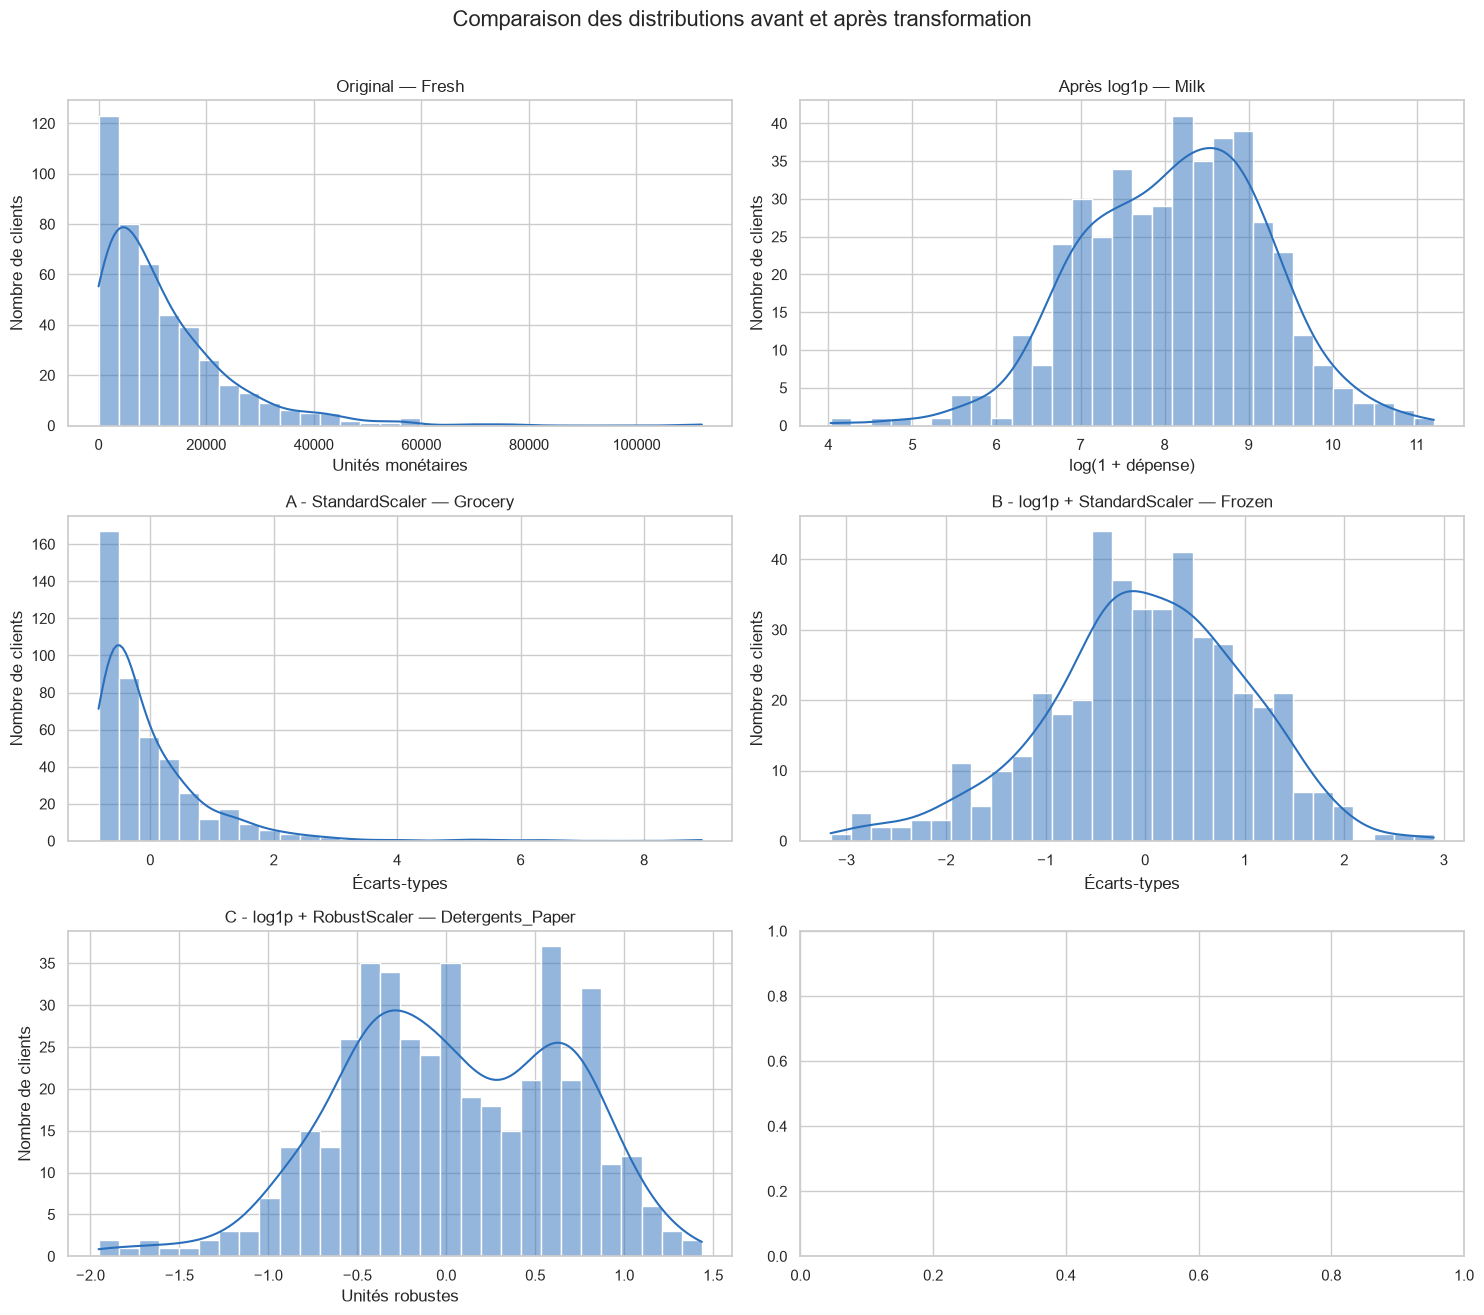

Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\07_preprocessing_distributions_comparison.png


In [5]:
sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
distribution_sets = [('Original', matrices['original'], 'Unités monétaires'), ('Après log1p', matrices['log1p'], 'log(1 + dépense)'), ('A - StandardScaler', matrices['standard_scaled'], 'Écarts-types'), ('B - log1p + StandardScaler', matrices['log_standard_scaled'], 'Écarts-types'), ('C - log1p + RobustScaler', matrices['log_robust_scaled'], 'Unités robustes')]
for ax, (title, matrix, xlabel) in zip(axes.flat, distribution_sets[:6]):
    col = SPENDING_COLUMNS[list(axes.flat).index(ax) % len(SPENDING_COLUMNS)]
    sns.histplot(matrix[col], kde=True, bins=30, color='#2a6fbb', ax=ax)
    ax.set_title(f'{title} — {col}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Nombre de clients')
fig.suptitle('Comparaison des distributions avant et après transformation', fontsize=16, y=1.01)
fig.tight_layout()
distribution_path = figures_dir / '07_preprocessing_distributions_comparison.png'
fig.savefig(distribution_path, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', distribution_path)

## 6. Boxplots avant et après

Les boxplots confirment visuellement le rôle des transformations. Les outliers ne sont pas supprimés. La comparaison reste faite dans chaque espace avec ses propres unités ; les hauteurs ne sont donc pas directement interprétables comme des montants communs.

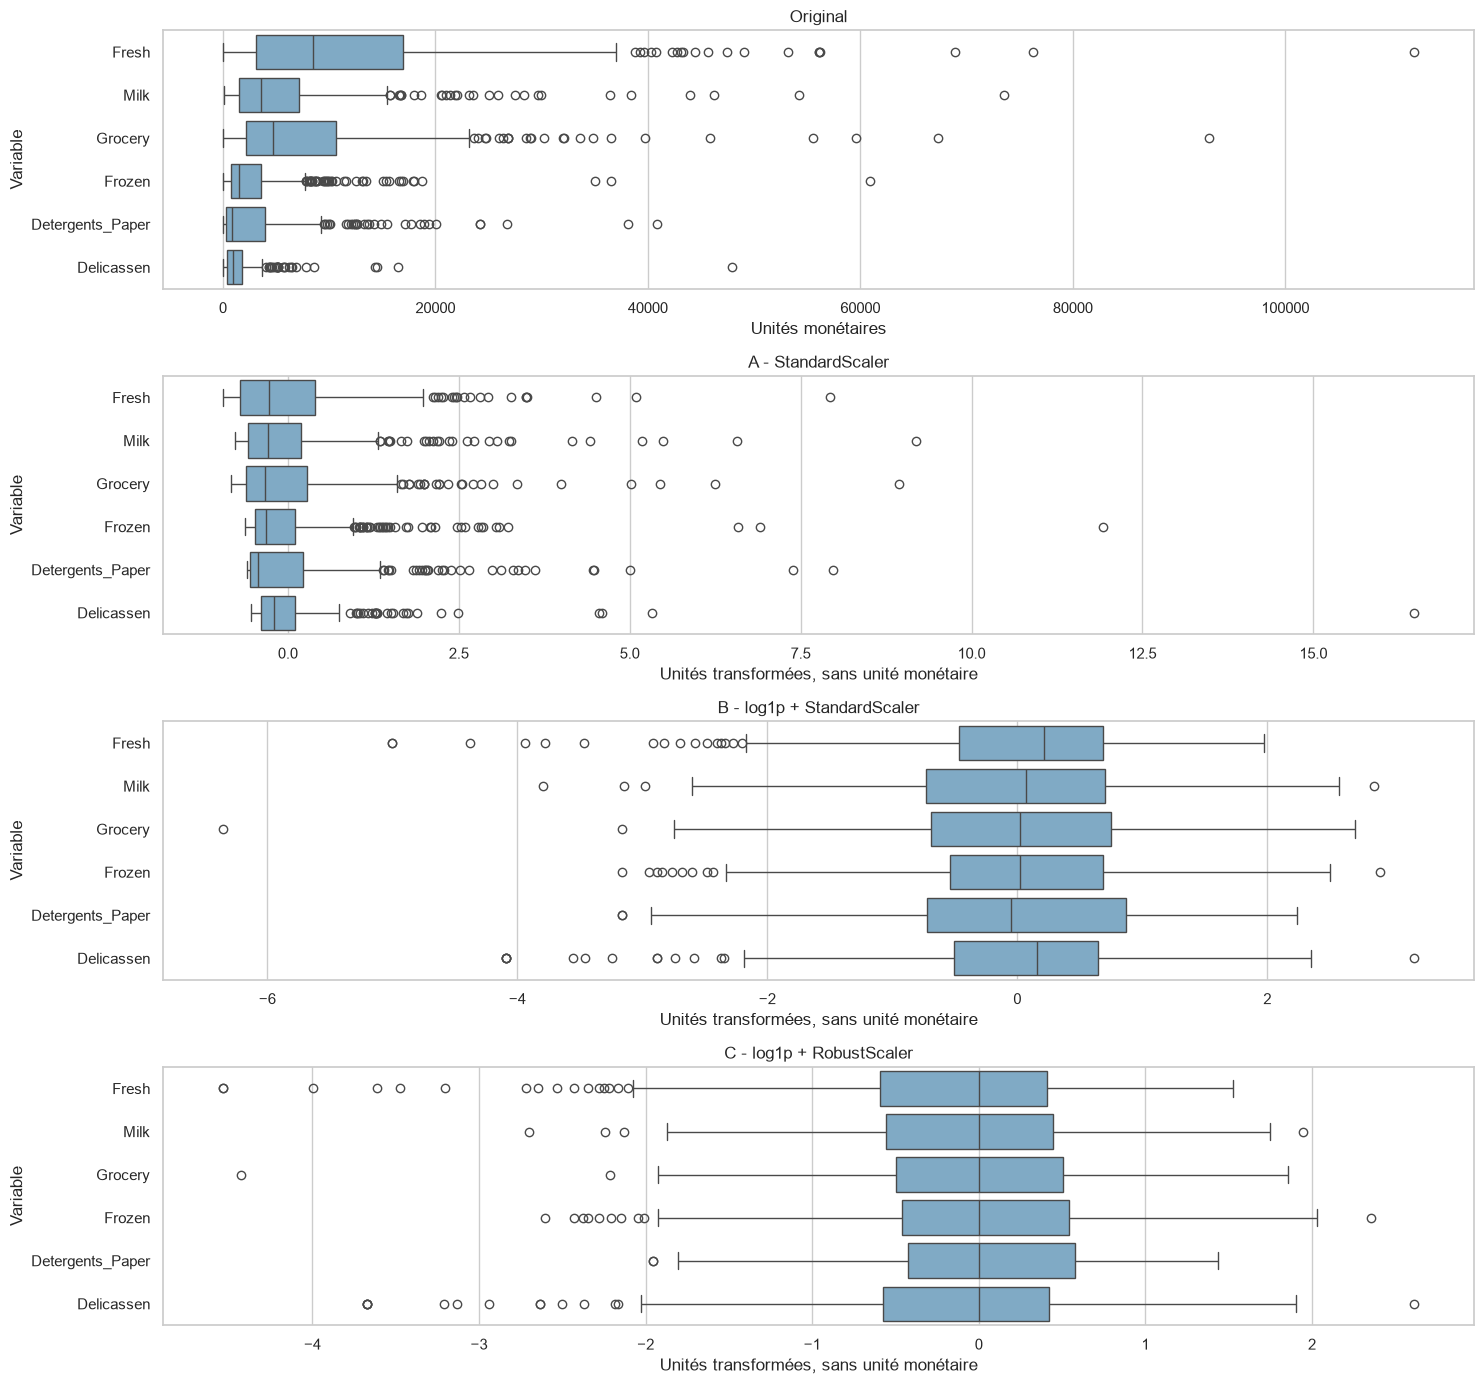

,Stratégie,Variable,Skewness
0,Original,Fresh,2.561
1,Original,Milk,4.054
2,Original,Grocery,3.587
3,Original,Frozen,5.908
4,Original,Detergents_Paper,3.632
5,Original,Delicassen,11.152
18,B - log1p + StandardScaler,Fresh,-1.575
19,B - log1p + StandardScaler,Milk,-0.224
20,B - log1p + StandardScaler,Grocery,-0.675
21,B - log1p + StandardScaler,Frozen,-0.353


Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\08_preprocessing_boxplots_comparison.png


In [6]:
boxplot_sets = [('Original', matrices['original']), ('A - StandardScaler', matrices['standard_scaled']), ('B - log1p + StandardScaler', matrices['log_standard_scaled']), ('C - log1p + RobustScaler', matrices['log_robust_scaled'])]
fig, axes = plt.subplots(4, 1, figsize=(15, 14))
for ax, (title, matrix) in zip(axes, boxplot_sets):
    sns.boxplot(data=matrix[SPENDING_COLUMNS], orient='h', color='#74add1', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Unités monétaires' if title == 'Original' else 'Unités transformées, sans unité monétaire')
    ax.set_ylabel('Variable')
fig.tight_layout()
boxplot_path = figures_dir / '08_preprocessing_boxplots_comparison.png'
fig.savefig(boxplot_path, bbox_inches='tight')
plt.show()
display(stats[stats['Stratégie'].isin(['Original', 'B - log1p + StandardScaler', 'C - log1p + RobustScaler'])][['Stratégie', 'Variable', 'Skewness']].round(3))
print('Figure enregistrée :', boxplot_path)

## 7. Vérification pédagogique des distances

La distance euclidienne dépend de l'échelle des variables. Une dépense de grande amplitude peut contribuer davantage à la distance qu'une dépense de petite amplitude, même si cette différence n'est pas la plus pertinente commercialement. Les distances ci-dessous utilisent quelques paires fixes de clients ; les valeurs des espaces transformés ne sont pas directement comparables en valeur absolue, car les coordonnées ont changé.

In [7]:
pairs = [(0, 1), (10, 100), (50, 300)]
distance_rows = []
for i, j in pairs:
    for name in ['original', 'standard_scaled', 'log_standard_scaled', 'log_robust_scaled']:
        values = matrices[name].to_numpy()
        distance_rows.append({'Client i': i, 'Client j': j, 'Espace': name, 'Distance euclidienne': np.linalg.norm(values[i] - values[j])})
distances = pd.DataFrame(distance_rows)
display(distances.round(3))
print('Ces exemples illustrent la sensibilité de la distance au choix de représentation, sans établir un classement définitif des stratégies.')

,Client i,Client j,Espace,Distance euclidienne
0,0,1,original,6206.256
1,0,1,standard_scaled,0.621
2,0,1,log_standard_scaled,1.723
3,0,1,log_robust_scaled,1.411
4,10,100,original,9013.254
5,10,100,standard_scaled,0.993
6,10,100,log_standard_scaled,1.046
7,10,100,log_robust_scaled,0.883
8,50,300,original,12757.551
9,50,300,standard_scaled,1.390


Ces exemples illustrent la sensibilité de la distance au choix de représentation, sans établir un classement définitif des stratégies.


## 8. Validations et export

Les assertions suivantes vérifient les dimensions, les colonnes, l'absence de NaN et d'infinis, le centrage-réduction de StandardScaler, la cohérence des index et l'intégrité du CSV original.

In [8]:
for name in ['standard_scaled', 'log_standard_scaled', 'log_robust_scaled']:
    matrix = matrices[name]
    assert matrix.shape == (440, 6)
    assert list(matrix.columns) == SPENDING_COLUMNS
    assert matrix.index.equals(df.index)
    assert not matrix.isna().any().any()
    assert not np.isinf(matrix.to_numpy()).any()
assert np.allclose(matrices['standard_scaled'].mean().to_numpy(), 0, atol=1e-12)
assert np.allclose(matrices['standard_scaled'].std(ddof=0).to_numpy(), 1, atol=1e-12)
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == original_hash_before
print('Toutes les validations sont réussies.')
print('440 lignes et 6 colonnes conservées dans chaque matrice.')
print('Aucune valeur NaN ou infinie.')
print('Le CSV original est inchangé.')

Toutes les validations sont réussies.
440 lignes et 6 colonnes conservées dans chaque matrice.
Aucune valeur NaN ou infinie.
Le CSV original est inchangé.


## 9. Conclusion scientifique

La stratégie B, log1p puis StandardScaler, est retenue comme candidate principale pour commencer le futur clustering car elle réduit l'effet des fortes asymétries tout en donnant une échelle comparable aux six dépenses. Cette recommandation n'est pas une victoire expérimentale : les scores des algorithmes n'ont pas encore été calculés.

La stratégie A sera conservée comme référence sans transformation logarithmique, et la stratégie C comme analyse de sensibilité plus robuste aux valeurs extrêmes. Le choix final devra être comparé avec les mêmes algorithmes, paramètres documentés et métriques.

In [9]:
print('Matrices exportées :', len(saved_paths))
print('Candidate principale pour le prochain clustering : B - log1p + StandardScaler')
print('Sensibilités conservées : A - StandardScaler et C - log1p + RobustScaler')
print('Aucun algorithme de clustering n a été entraîné.')

Matrices exportées :

 3
Candidate principale pour le prochain clustering : B - log1p + StandardScaler
Sensibilités conservées : A - StandardScaler et C - log1p + RobustScaler
Aucun algorithme de clustering n a été entraîné.
